# Double Well Potential with Path Integral MCMC

PHYS 142/242 Final Project, Problem 1.

We sample closed imaginary-time paths of a particle in the double well

$$V(x) = \alpha x^4 - 2x^2 + \frac{1}{\alpha} = \alpha\left(x^2 - \frac{1}{\alpha}\right)^2, \qquad \alpha = 0.4,\quad m = \hbar = 1,$$

with the discretized Euclidean action

$$S_E(x) = \sum_{i=0}^{N-1}\left[\frac{(x_{i+1}-x_i)^2}{2\,\delta\tau} + \delta\tau\, V(x_i)\right], \qquad x_N \equiv x_0,\quad \delta\tau = \beta/N,$$

and recover $E_0$, $\Delta E = E_1 - E_0$, and the position distribution from the paths alone. The eigenstates of the discretized Hamiltonian from Assignment 2 are the benchmark throughout.

The notebook has four parts: the eigenstate benchmark, the sampler and error analysis tools, and Problems A, B, and C. Run the cells in order. The full notebook takes a few minutes on a laptop.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from concurrent.futures import ThreadPoolExecutor
from numba import njit
from scipy.linalg import eigh_tridiagonal
from scipy.optimize import curve_fit

plt.rcParams.update({
    "font.size": 12,
    "figure.figsize": (6.4, 3.8),
    "figure.dpi": 100,
    "figure.constrained_layout.use": True,
})
BLUE, RED, GRAY, GOLD = "#007c91", "#a54632", "#8a97a6", "#e0a53a"

ALPHA = 0.4
X_MIN = 1 / np.sqrt(ALPHA)
SEED = 142
N_CHAINS = 8

## Benchmark: eigenstates of the discretized Hamiltonian

As in Assignment 2, we discretize $\hat H = -\tfrac12 \partial_x^2 + V(x)$ with second-order finite differences on $[-L, L]$ and diagonalize the tridiagonal matrix. Problem B(i) of Assignment 2 gives the reference values of $E_0$ and $E_1$ at $\alpha = 0.4$.

In [2]:
@njit(nogil=True)
def potential(x):
    return ALPHA * x**4 - 2 * x**2 + 1 / ALPHA


def eigenstates(n_states, half_width=6.0, n_grid=4800):
    x = np.linspace(-half_width, half_width, n_grid + 1)[1:-1]
    dx = x[1] - x[0]
    diagonal = 1 / dx**2 + potential(x)
    off_diagonal = np.full(x.size - 1, -0.5 / dx**2)
    energies, states = eigh_tridiagonal(diagonal, off_diagonal, select="i",
                                        select_range=(0, n_states - 1))
    states /= np.sqrt(dx)
    return x, dx, energies, states


x_grid, dx, E, phi = eigenstates(40)
GAP = E[1] - E[0]
X01 = abs(dx * np.sum(phi[:, 0] * x_grid * phi[:, 1]))
REFERENCE = (1.2345071627860, 1.3469408689225)

print(f"E0 = {E[0]:.7f}   (Assignment 2 reference {REFERENCE[0]:.7f})")
print(f"E1 = {E[1]:.7f}   (Assignment 2 reference {REFERENCE[1]:.7f})")
print(f"Delta E = E1 - E0 = {GAP:.5f},   1/Delta E = {1 / GAP:.2f}")
print(f"E2 - E0 = {E[2] - E[0]:.4f},   1/(E2 - E0) = {1 / (E[2] - E[0]):.3f}")
print(f"|<phi0|x|phi1>| = {X01:.4f}")

E0 = 1.2345061   (Assignment 2 reference 1.2345072)
E1 = 1.3469396   (Assignment 2 reference 1.3469409)
Delta E = E1 - E0 = 0.11243,   1/Delta E = 8.89
E2 - E0 = 1.7750,   1/(E2 - E0) = 0.563
|<phi0|x|phi1>| = 1.3512


## The sampler

One sweep proposes $x_i \to x_i + u$, $u \sim U(-h, h)$, at every slice in turn and accepts with probability $\min(1, e^{-\Delta S_E})$. Only the two links touching slice $i$ and its potential term change, so each proposal costs $O(1)$.

Problem B also asks about a move that shifts the whole path, $x_i \to x_i + d$ with $d \sim U(-d_{\max}, d_{\max})$. It leaves every kinetic term unchanged, so only $\delta\tau\sum_i [V(x_i + d) - V(x_i)]$ enters the acceptance. Both proposals are symmetric, so plain Metropolis acceptance is correct.

The energy uses the virial estimator, $V + \tfrac12 x V' = 3\alpha x^4 - 4x^2 + 1/\alpha$, averaged over slices after every sweep. Paths are saved every `SAVE_EVERY` sweeps for histograms and correlation functions. The inner loops are compiled with Numba, and independent chains run in parallel threads (`nogil=True`), each with its own seeded generator.

In [3]:
@njit(nogil=True)
def virial_energy(x):
    return 3 * ALPHA * x**4 - 4 * x**2 + 1 / ALPHA


@njit(nogil=True)
def local_sweep(path, dtau, hit_size, rng):
    n = path.size
    accepted = 0
    for i in range(n):
        left, old, right = path[i - 1], path[i], path[(i + 1) % n]
        new = old + rng.uniform(-hit_size, hit_size)
        kinetic = ((right - new)**2 + (new - left)**2
                   - (right - old)**2 - (old - left)**2) / (2 * dtau)
        change = kinetic + dtau * (potential(new) - potential(old))
        if change <= 0 or rng.random() < np.exp(-change):
            path[i] = new
            accepted += 1
    return accepted


@njit(nogil=True)
def shift_path(path, dtau, shift_size, rng):
    d = rng.uniform(-shift_size, shift_size)
    change = 0.0
    for x in path:
        change += potential(x + d) - potential(x)
    change *= dtau
    if change <= 0 or rng.random() < np.exp(-change):
        path += d
        return 1
    return 0


@njit(nogil=True)
def sample_paths(path, dtau, hit_size, shift_size, sweeps, save_every, rng):
    energy = np.empty(sweeps)
    center = np.empty(sweeps)
    saved = np.empty((sweeps // save_every, path.size))
    local_accepted = 0
    shifts_accepted = 0
    for sweep in range(sweeps):
        local_accepted += local_sweep(path, dtau, hit_size, rng)
        if shift_size > 0:
            shifts_accepted += shift_path(path, dtau, shift_size, rng)
        total = 0.0
        for x in path:
            total += virial_energy(x)
        energy[sweep] = total / path.size
        center[sweep] = path.mean()
        if (sweep + 1) % save_every == 0:
            saved[sweep // save_every] = path
    return energy, center, saved, local_accepted / (sweeps * path.size), shifts_accepted / sweeps

### Running chains and measuring

Every chain starts cold, with all slices at the right-hand minimum $x_i = +1/\sqrt{\alpha}$, and the first 10% of its sweeps are discarded as burn-in. The hit size scales with the width of the free-particle link, $h = 2.5\sqrt{\delta\tau}$, which gives an acceptance rate near 43% at every $\delta\tau$.

The correlation function is averaged over all pairs of slices separated by $\tau$. For one periodic path that is the circular autocorrelation $\frac1N\sum_i x_i x_{i+k}$, which the FFT computes for every $k$ at once.

In [4]:
BURN_IN_FRACTION = 0.1
SAVE_EVERY = 50
N_BLOCKS = 8
BINS = np.linspace(-4, 4, 161)
BIN_CENTERS = 0.5 * (BINS[1:] + BINS[:-1])


def path_correlation(paths):
    spectrum = np.fft.rfft(paths, axis=1)
    return np.fft.irfft(np.abs(spectrum)**2, n=paths.shape[1], axis=1) / paths.shape[1]


def block_means(values, n_blocks=N_BLOCKS):
    return np.array([block.mean(axis=0) for block in np.array_split(values, n_blocks)])


def run_chain(beta, dtau, sweeps, seed, shift_size=0.0, save_every=SAVE_EVERY):
    path = np.full(int(round(beta / dtau)), X_MIN)
    rng = np.random.default_rng(seed)
    energy, center, saved, acceptance, shift_acceptance = sample_paths(
        path, dtau, 2.5 * np.sqrt(dtau), shift_size, sweeps, save_every, rng)
    burn_in = int(BURN_IN_FRACTION * sweeps)
    saved = saved[burn_in // save_every:]
    return {
        "energy": energy[burn_in:],
        "center": center[burn_in:],
        "center_trace": center,
        "histogram": np.histogram(saved, BINS)[0],
        "correlation": block_means(path_correlation(saved)),
        "examples": saved[::len(saved) // 3][:3],
        "acceptance": acceptance,
        "shift_acceptance": shift_acceptance,
    }


def run_chains(beta, dtau, sweeps, seed, shift_size=0.0, save_every=SAVE_EVERY, n_chains=N_CHAINS):
    with ThreadPoolExecutor(n_chains) as pool:
        jobs = [pool.submit(run_chain, beta, dtau, sweeps, seed + k, shift_size, save_every)
                for k in range(n_chains)]
        return [job.result() for job in jobs]

### Error analysis (Lab 12)

Consecutive sweeps are strongly correlated, so $s/\sqrt{n}$ is far too small. We use two tools from Lab 12:

* **Blocking.** Each chain is cut into `N_BLOCKS` consecutive blocks. With 8 chains this gives 64 block means, and each block (tens of thousands of sweeps) is much longer than the autocorrelation time, so the block means are nearly independent. The standard error of the mean is $s_{\text{blocks}}/\sqrt{64}$. The same blocks feed a jackknife for nonlinear quantities such as fitted parameters.
* **Integrated autocorrelation time** $\tau_{\text{int}} = \tfrac12 + \sum_{k\ge1}\rho(k)$, summed up to the first window $W \ge 5\,\tau_{\text{int}}(W)$, so that the effective number of measurements is $n/(2\tau_{\text{int}})$.

In [5]:
def autocorrelation(values):
    centered = values - values.mean()
    spectrum = np.fft.rfft(centered, 2 * len(centered))
    acf = np.fft.irfft(np.abs(spectrum)**2)[:len(centered)]
    return acf / acf[0]


def integrated_time(values, c=5):
    tau = 0.5 + np.cumsum(autocorrelation(values)[1:])
    window = np.flatnonzero(np.arange(1, len(tau) + 1) >= c * tau)
    return tau[window[0]] if len(window) else tau[-1]


def blocked_mean(chains, key="energy"):
    blocks = np.concatenate([block_means(chain[key]) for chain in chains])
    return blocks.mean(), blocks.std(ddof=1) / np.sqrt(len(blocks))


def jackknife(blocks, statistic):
    k = len(blocks)
    replicas = np.array([statistic((blocks.sum(axis=0) - b) / (k - 1)) for b in blocks])
    error = np.sqrt((k - 1) / k * np.sum((replicas - replicas.mean(axis=0))**2, axis=0))
    return statistic(blocks.mean(axis=0)), error


def mean_time(chains, key):
    return np.mean([integrated_time(chain[key]) for chain in chains])


def well_changes(center, level=X_MIN / 2):
    side = np.sign(center[np.abs(center) > level])
    return np.count_nonzero(side[1:] != side[:-1])


def density(counts):
    return counts / (counts.sum() * (BINS[1] - BINS[0]))

## Problem A: Ground state

### How large must $\beta$ be?

At inverse temperature $\beta$ the virial estimator measures $\langle \hat H\rangle_\beta = \sum_n E_n e^{-\beta E_n} / \sum_n e^{-\beta E_n}$, not $E_0$. Because $E_2 - E_0 \approx 1.77$, all states above $\phi_1$ are gone once $\beta \gtrsim 3$. But $\phi_1$ lies only $\Delta E \approx 0.112$ above $\phi_0$, and for $1/(E_2-E_0) \ll \beta \ll 1/\Delta E$ both states are equally populated, so the estimator gives $(E_0+E_1)/2$, the energy of a particle localized in one well. The bias only becomes small once $\beta \Delta E \gg 1$.

In [6]:
def thermal_energy(beta, energies=E):
    weights = np.exp(-beta * (energies - energies[0]))
    return np.sum(weights * energies) / weights.sum()


print(" beta   beta*dE   <H>_beta - E0")
for beta in [1, 3, 9, 20, 40, 80]:
    print(f"{beta:5d}   {beta * GAP:6.2f}    {thermal_energy(beta) - E[0]:.5f}")

 beta   beta*dE   <H>_beta - E0
    1     0.11    0.30048
    3     0.34    0.05208
    9     1.01    0.02998
   20     2.25    0.01073
   40     4.50    0.00124
   80     8.99    0.00001


We use $\beta = 40$ ($\beta\Delta E = 4.5$). The remaining bias, $1.2\times10^{-3}$, is below our statistical error, and the histogram is $|\phi_0|^2$ mixed with 1.1% of $|\phi_1|^2$, which differs from $|\phi_0|^2$ only near the barrier. Larger $\beta$ would cost more sweeps for no visible gain: the number of slices grows with $\beta$, and so does the time the chain needs to move between wells (Problem B).

### Dependence on $\delta\tau$

The primitive action is accurate to $O(\delta\tau^2)$, so we run 8 chains of 400,000 sweeps at several $\delta\tau$ and extrapolate $E(\delta\tau) = E_0 + c\,\delta\tau^2$ with a weighted least-squares fit.

In [7]:
BETA_A = 40
DTAUS = [0.25, 0.2, 0.15, 0.1, 0.07]
SWEEPS_A = 400_000

runs_a = {}
for k, dtau in enumerate(DTAUS):
    runs_a[dtau] = run_chains(BETA_A, dtau, SWEEPS_A, seed=SEED + 100 * k)

energies_a = np.array([blocked_mean(runs_a[dtau]) for dtau in DTAUS])
print(" dtau     N   accept   E (blocked)          tau_int(E)")
for dtau, (value, error) in zip(DTAUS, energies_a):
    chains = runs_a[dtau]
    print(f"{dtau:5.2f} {int(round(BETA_A / dtau)):5d}   {chains[0]['acceptance']:.2f}"
          f"    {value:.4f} +/- {error:.4f}     {mean_time(chains, 'energy'):5.1f}")

 dtau     N   accept   E (blocked)          tau_int(E)


 0.25   160   0.41    1.1741 +/- 0.0014       6.5


 0.20   200   0.42    1.1948 +/- 0.0015       9.3
 0.15   267   0.42    1.2133 +/- 0.0021      15.4


 0.10   400   0.43    1.2299 +/- 0.0030      32.8
 0.07   571   0.43    1.2292 +/- 0.0042      64.9


Extrapolated E0 = 1.2361 +/- 0.0021  (slope -1.00, chi2 = 2.6 for 3 dof)
Eigenstates:  E0 = 1.2345,  <H>_beta=40 = 1.2357


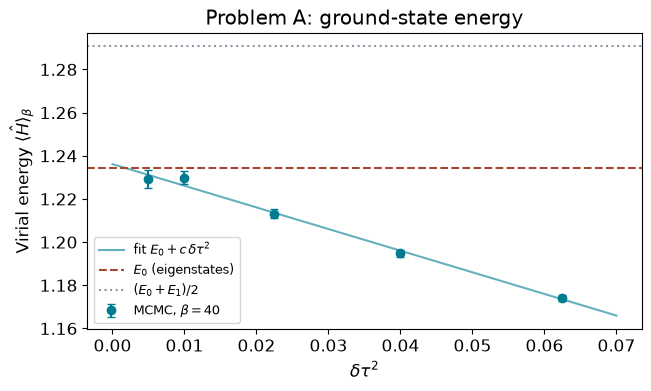

In [8]:
dtau2 = np.array(DTAUS)**2
design = np.column_stack((np.ones_like(dtau2), dtau2)) / energies_a[:, 1, None]
coefficients, *_ = np.linalg.lstsq(design, energies_a[:, 0] / energies_a[:, 1], rcond=None)
covariance = np.linalg.inv(design.T @ design)
E0_MC, E0_MC_ERROR = coefficients[0], np.sqrt(covariance[0, 0])
chi2 = np.sum((design @ coefficients - energies_a[:, 0] / energies_a[:, 1])**2)

print(f"Extrapolated E0 = {E0_MC:.4f} +/- {E0_MC_ERROR:.4f}  (slope {coefficients[1]:.2f}, "
      f"chi2 = {chi2:.1f} for {len(DTAUS) - 2} dof)")
print(f"Eigenstates:  E0 = {E[0]:.4f},  <H>_beta=40 = {thermal_energy(BETA_A):.4f}")

grid = np.linspace(0, 0.07, 50)
fig, ax = plt.subplots()
ax.errorbar(dtau2, energies_a[:, 0], yerr=energies_a[:, 1], fmt="o", color=BLUE,
            capsize=3, label=r"MCMC, $\beta = 40$")
ax.plot(grid, coefficients[0] + coefficients[1] * grid, color=BLUE, alpha=0.6,
        label=r"fit $E_0 + c\,\delta\tau^2$")
ax.axhline(E[0], color=RED, linestyle="--", label=r"$E_0$ (eigenstates)")
ax.axhline(0.5 * (E[0] + E[1]), color=GRAY, linestyle=":", label=r"$(E_0+E_1)/2$")
ax.set(xlabel=r"$\delta\tau^2$", ylabel=r"Virial energy $\langle \hat H\rangle_\beta$",
       title="Problem A: ground-state energy")
ax.legend(fontsize=9)
plt.show()

### Ground-state density

Histogram of every $x_i$ from the saved paths (every 50th sweep after burn-in, all slices, all chains), compared with $|\phi_0(x)|^2$. The error bars come from the spread of the 8 independent chains.

With local moves the chain changes wells only a handful of times per run (Problem B), so the split of probability between the two wells converges far more slowly than the shape inside each well. We print that split, then use the parity of $V$ to average each histogram with its mirror image, $\rho(x) \to [\rho(x) + \rho(-x)]/2$, which removes the slow mode from the shape comparison.

 dtau   fraction in right well   chi2/bin vs |phi0|^2 (symmetrized)
 0.25       0.477 +/- 0.022              307.27
 0.20       0.492 +/- 0.018              125.26
 0.15       0.466 +/- 0.041              37.36
 0.10       0.514 +/- 0.038              5.85
 0.07       0.614 +/- 0.053              1.74


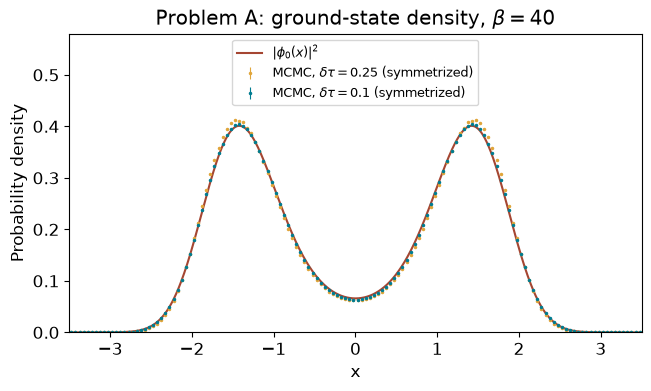

In [9]:
def histogram_with_errors(chains, symmetrize=False):
    per_chain = np.array([density(chain["histogram"]) for chain in chains])
    if symmetrize:
        per_chain = 0.5 * (per_chain + per_chain[:, ::-1])
    return per_chain.mean(axis=0), per_chain.std(axis=0, ddof=1) / np.sqrt(len(chains))


phi0_squared = np.interp(BIN_CENTERS, x_grid, phi[:, 0]**2)
print(" dtau   fraction in right well   chi2/bin vs |phi0|^2 (symmetrized)")
for dtau in DTAUS:
    right = [chain["histogram"][BIN_CENTERS > 0].sum() / chain["histogram"].sum() for chain in runs_a[dtau]]
    mean, error = histogram_with_errors(runs_a[dtau], symmetrize=True)
    chi2_per_bin = np.mean(((mean - phi0_squared)[error > 0] / error[error > 0])**2)
    print(f"{dtau:5.2f}       {np.mean(right):.3f} +/- {np.std(right, ddof=1) / np.sqrt(len(right)):.3f}"
          f"              {chi2_per_bin:.2f}")

fig, ax = plt.subplots()
for dtau, color in [(0.25, GOLD), (0.1, BLUE)]:
    mean, error = histogram_with_errors(runs_a[dtau], symmetrize=True)
    ax.errorbar(BIN_CENTERS, mean, yerr=error, fmt=".", markersize=3, color=color,
                elinewidth=0.8, label=fr"MCMC, $\delta\tau = {dtau}$ (symmetrized)")
ax.plot(x_grid, phi[:, 0]**2, color=RED, label=r"$|\phi_0(x)|^2$")
ax.set(xlabel="x", ylabel="Probability density", xlim=(-3.5, 3.5), ylim=(0, 0.58),
       title=r"Problem A: ground-state density, $\beta = 40$")
ax.legend(fontsize=9, loc="upper center")
plt.show()

### Discussion

**Energy.** The virial energy falls linearly in $\delta\tau^2$ with slope $c \approx -1.0$, so $\delta\tau = 0.25$ underestimates $E_0$ by 5% while $\delta\tau = 0.1$ is already within $0.005$. The extrapolation gives $E_0 = 1.2361 \pm 0.0021$, against $E_0 = 1.2345$ from the eigenstates ($0.8\sigma$) and $\langle\hat H\rangle_{\beta=40} = 1.2357$ ($0.2\sigma$), with $\chi^2 = 2.6$ for 3 degrees of freedom. The dotted line, $(E_0+E_1)/2 = 1.291$, is what a chain stuck in one well would report; every point is far below it, so the chains do sample paths that tunnel.

**Density.** Inside each well the symmetrized histogram follows $|\phi_0|^2$, including the small but nonzero density under the barrier, which comes from the paths that tunnel. At $\delta\tau = 0.25$ the peaks are too high and the barrier region too low ($\chi^2/\text{bin} \approx 300$ with these small error bars); the deviation shrinks steadily with $\delta\tau$, to $\chi^2/\text{bin} = 1.7$ at $\delta\tau = 0.07$. The unsymmetrized well populations are the slow part: at $\delta\tau = 0.07$ the chains spend $61 \pm 5\%$ of their time in the right well, the one they started in.

**Cost of small $\delta\tau$.** $\tau_{\text{int}}(E)$ grows from 6.5 to 65 sweeps as $N$ grows from 160 to 571, close to the $N^2$ expected for local moves, so each halving of $\delta\tau$ costs about $2 \times 4$ in run time. This is why we extrapolate from moderate $\delta\tau$ instead of running at very small $\delta\tau$.

**Strategy.**

* $\beta = 40$, so $\beta\Delta E = 4.5$ and the thermal bias ($1.2\times10^{-3}$) is below the statistical error. Comparing $\beta$ only with $1/(E_2-E_0) \approx 0.56$ would suggest $\beta \approx 5$ is plenty, but that gives the energy of a localized particle, $\approx (E_0+E_1)/2$.
* $\delta\tau$ from 0.25 to 0.07, extrapolated as $\delta\tau^2$.
* Initial configuration: every slice at the right minimum. A cold start in one well is the hardest test of tunneling: the chain has to find the other well on its own.
* Burn-in: the first 10% (40,000 sweeps), more than $500\,\tau_{\text{int}}(E)$ at every $\delta\tau$ and long enough for the number of kinks in the path to settle.
* Hit size $h = 2.5\sqrt{\delta\tau}$, giving 41–43% acceptance at every $\delta\tau$.
* 8 independent chains of 400,000 sweeps at each $\delta\tau$, with errors from 64 blocks of 45,000 sweeps.
* No thinning of the energy, which is cheap to measure every sweep and loses nothing by being correlated. Paths are stored every 50 sweeps only to bound memory and the cost of histogramming.

## Problem B: Tunneling in imaginary time

### Two-state form of $C(\tau)$

With $x(\tau) = e^{\tau \hat H} x e^{-\tau \hat H}$ and $Z = \sum_n e^{-\beta E_n}$, the cyclic trace gives

$$C(\tau) = \langle x(0)x(\tau)\rangle_\beta = \frac1Z \operatorname{Tr}\!\left[e^{-(\beta-\tau)\hat H}\, x\, e^{-\tau \hat H}\, x\right] = \frac1Z\sum_{m,n} e^{-(\beta-\tau)E_m}\, e^{-\tau E_n}\,|\langle \phi_m|x|\phi_n\rangle|^2 .$$

A term with $n \ge 2$ is suppressed by $e^{-(E_n-E_0)\tau}$, and one with $m \ge 2$ by $e^{-(E_m-E_0)(\beta-\tau)}$, so once $\tau$ and $\beta - \tau$ are a few times $1/(E_2-E_0) \approx 0.56$ only $m, n \in \{0, 1\}$ survive. The potential is even, so $\phi_0$ is even, $\phi_1$ is odd, and $\langle\phi_0|x|\phi_0\rangle = \langle\phi_1|x|\phi_1\rangle = 0$. Keeping the two cross terms,

$$C(\tau) \approx |x_{01}|^2\,\frac{e^{-(\beta-\tau)E_0 - \tau E_1} + e^{-(\beta-\tau)E_1 - \tau E_0}}{e^{-\beta E_0} + e^{-\beta E_1}} .$$

Multiplying numerator and denominator by $e^{\beta(E_0+E_1)/2}$ turns the numerator into $2\cosh[\Delta E(\tau - \beta/2)]$ and the denominator into $2\cosh(\beta\Delta E/2)$:

$$C(\tau) \approx |\langle\phi_0|x|\phi_1\rangle|^2\,\frac{\cosh[\Delta E(\tau-\beta/2)]}{\cosh(\beta\Delta E/2)} .$$

### Choice of $\beta$ and the runs

We take $\beta = 20$ ($\beta\Delta E = 2.25$), so $C(\tau)$ has visible curvature: it falls by a factor $\cosh(1.12) \approx 1.7$ between $\tau = 0$ and $\beta/2$, which separates $\Delta E$ from the amplitude. A much larger $\beta$ leaves only the decaying exponential and makes the midpoint value tiny and noisy. We use $\delta\tau = 0.1$ ($N = 200$) and run 8 chains of $2\times10^6$ sweeps (paths saved every 200 sweeps), first with local moves only and then with one whole-path shift per sweep, $d_{\max} = 2/\sqrt{\alpha}$, the distance between the minima.

In [10]:
BETA_B = 20
DTAU_B = 0.1
SWEEPS_B = 2_000_000
SHIFT_SIZE = 2 * X_MIN
TAU_B = np.arange(int(round(BETA_B / DTAU_B))) * DTAU_B

runs_b = {
    "local moves": run_chains(BETA_B, DTAU_B, SWEEPS_B, seed=SEED + 1000, save_every=200),
    "local + shift": run_chains(BETA_B, DTAU_B, SWEEPS_B, seed=SEED + 2000, shift_size=SHIFT_SIZE,
                                save_every=200),
}

In [11]:
def two_state(tau, amplitude, gap, beta=BETA_B):
    return amplitude * np.cosh(gap * (tau - beta / 2)) / np.cosh(beta * gap / 2)


def fit_two_state(correlation, tau_min):
    keep = (TAU_B >= tau_min) & (TAU_B <= BETA_B / 2)
    amplitude, gap = curve_fit(two_state, TAU_B[keep], correlation[keep], p0=(1.8, 0.1))[0]
    return np.array([gap, np.sqrt(amplitude)])


def fit_correlation(blocks, tau_min):
    return jackknife(blocks, lambda correlation: fit_two_state(correlation, tau_min))


X_MATRIX = dx * phi.T @ (x_grid[:, None] * phi)


def spectral_correlation(tau, beta=BETA_B):
    levels = E - E[0]
    terms = [np.exp(-(beta - t) * levels[:, None] - t * levels[None, :]) * X_MATRIX**2 for t in tau]
    return np.array([term.sum() for term in terms]) / np.exp(-beta * levels).sum()


exact_correlation = spectral_correlation(TAU_B)
print(f"Eigenstates: Delta E = {GAP:.4f}, |x01| = {X01:.4f}")
for tau_min in [1.5, 2.5, 4.0]:
    gap, x01 = fit_two_state(exact_correlation, tau_min)
    print(f"  same fit applied to the exact C(tau), tau in [{tau_min}, {BETA_B / 2:g}]:"
          f"  Delta E = {gap:.4f},  |x01| = {x01:.4f}")
print()
fits_b = {}
for name, chains in runs_b.items():
    blocks = np.concatenate([chain["correlation"] for chain in chains])
    print(f"{name}:")
    for tau_min in [1.5, 2.5, 4.0]:
        (gap, x01), (gap_error, x01_error) = fit_correlation(blocks, tau_min)
        fits_b[name, tau_min] = (gap, gap_error, x01, x01_error)
        print(f"  fit tau in [{tau_min}, {BETA_B / 2:g}]:  Delta E = {gap:.4f} +/- {gap_error:.4f},"
              f"  |x01| = {x01:.4f} +/- {x01_error:.4f}")

Eigenstates: Delta E = 0.1124, |x01| = 1.3512
  same fit applied to the exact C(tau), tau in [1.5, 10]:  Delta E = 0.1126,  |x01| = 1.3521
  same fit applied to the exact C(tau), tau in [2.5, 10]:  Delta E = 0.1125,  |x01| = 1.3514
  same fit applied to the exact C(tau), tau in [4.0, 10]:  Delta E = 0.1124,  |x01| = 1.3512

local moves:
  fit tau in [1.5, 10]:  Delta E = 0.1108 +/- 0.0051,  |x01| = 1.3551 +/- 0.0037
  fit tau in [2.5, 10]:  Delta E = 0.1107 +/- 0.0053,  |x01| = 1.3544 +/- 0.0051
  fit tau in [4.0, 10]:  Delta E = 0.1104 +/- 0.0056,  |x01| = 1.3532 +/- 0.0069
local + shift:
  fit tau in [1.5, 10]:  Delta E = 0.1065 +/- 0.0032,  |x01| = 1.3505 +/- 0.0026
  fit tau in [2.5, 10]:  Delta E = 0.1060 +/- 0.0034,  |x01| = 1.3486 +/- 0.0036
  fit tau in [4.0, 10]:  Delta E = 0.1056 +/- 0.0037,  |x01| = 1.3466 +/- 0.0054


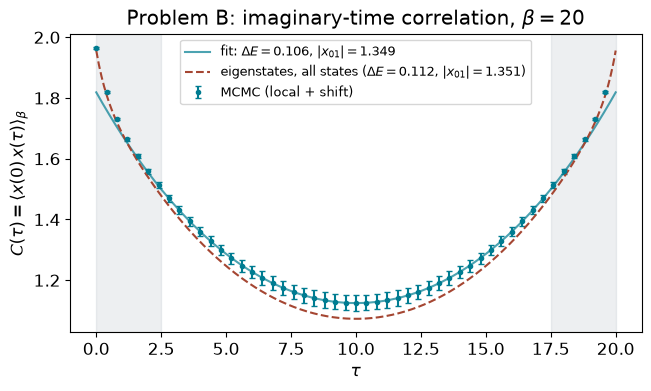

In [12]:
blocks = np.concatenate([chain["correlation"] for chain in runs_b["local + shift"]])
correlation, correlation_error = jackknife(blocks, lambda c: c)
gap, _, x01, _ = fits_b["local + shift", 2.5]
fine_tau = np.linspace(0, BETA_B, 400)

fig, ax = plt.subplots()
ax.errorbar(TAU_B[::4], correlation[::4], yerr=correlation_error[::4], fmt="o", markersize=3,
            color=BLUE, capsize=2, label="MCMC (local + shift)")
ax.plot(fine_tau, two_state(fine_tau, x01**2, gap), color=BLUE, alpha=0.7,
        label=fr"fit: $\Delta E = {gap:.3f}$, $|x_{{01}}| = {x01:.3f}$")
ax.plot(fine_tau, spectral_correlation(fine_tau), "--", color=RED,
        label=fr"eigenstates, all states ($\Delta E = {GAP:.3f}$, $|x_{{01}}| = {X01:.3f}$)")
ax.axvspan(0, 2.5, color=GRAY, alpha=0.15)
ax.axvspan(BETA_B - 2.5, BETA_B, color=GRAY, alpha=0.15)
ax.set(xlabel=r"$\tau$", ylabel=r"$C(\tau) = \langle x(0)\,x(\tau)\rangle_\beta$",
       title=r"Problem B: imaginary-time correlation, $\beta = 20$")
ax.legend(fontsize=9)
plt.show()

The dashed curve is the full spectral sum over 40 eigenstates. The shaded regions are left out of the fit: there $\phi_2, \phi_3, \dots$ still contribute, and $C(\tau)$ rises above the two-state form towards $\langle x^2\rangle_\beta$ at $\tau = 0$.

### Path center and sampled paths

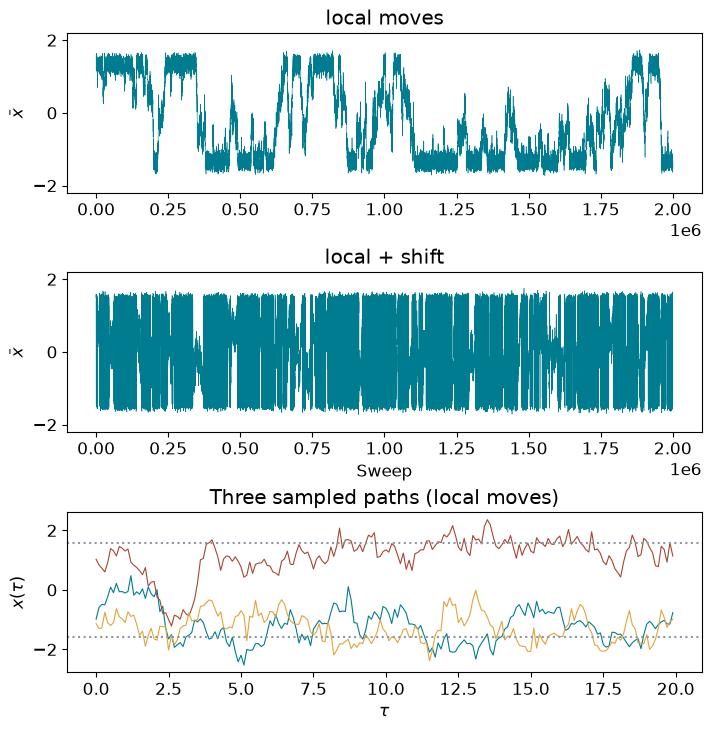

                   flips/chain   sweeps per flip   tau_int(x_bar)   tau_int(E)   shift accept


local moves              18           98630            45301         33.1        0.000


local + shift         19422              93              131         11.3        0.060


In [13]:
fig, axes = plt.subplots(3, 1, figsize=(7.0, 7.2))
for ax, (name, chains) in zip(axes[:2], runs_b.items()):
    center = chains[0]["center_trace"]
    ax.plot(np.arange(len(center))[::20], center[::20], color=BLUE, linewidth=0.4)
    ax.set(ylabel=r"$\bar x$", ylim=(-2.2, 2.2), title=name)
axes[1].set_xlabel("Sweep")
for path, color in zip(runs_b["local moves"][0]["examples"], [BLUE, RED, GOLD]):
    axes[2].plot(TAU_B, path, color=color, linewidth=0.8)
for level in (-X_MIN, X_MIN):
    axes[2].axhline(level, color=GRAY, linestyle=":")
axes[2].set(xlabel=r"$\tau$", ylabel=r"$x(\tau)$", title="Three sampled paths (local moves)")
plt.show()

print("                   flips/chain   sweeps per flip   tau_int(x_bar)   tau_int(E)   shift accept")
for name, chains in runs_b.items():
    flips = np.mean([well_changes(chain["center"]) for chain in chains])
    print(f"{name:15s}   {flips:9.0f}   {len(chains[0]['center']) / flips:13.0f}   {mean_time(chains, 'center'):14.0f}"
          f"   {mean_time(chains, 'energy'):10.1f}   {np.mean([c['shift_acceptance'] for c in chains]):10.3f}")

### Does the shift move help at larger $\beta$?

A short comparison at $\beta = 40$, where a typical path already contains a few kinks.

In [14]:
for name, shift_size in [("local moves", 0.0), ("local + shift", SHIFT_SIZE)]:
    chains = run_chains(40, 0.1, 300_000, seed=SEED + 3000, shift_size=shift_size)
    flips = np.mean([well_changes(chain["center"]) for chain in chains])
    print(f"beta = 40, {name:14s}: shift accept = {np.mean([c['shift_acceptance'] for c in chains]):.3f},"
          f"  flips/chain = {flips:5.0f},  tau_int(x_bar) = {mean_time(chains, 'center'):6.0f}")

beta = 40, local moves   : shift accept = 0.000,  flips/chain =     2,  tau_int(x_bar) =  20926


beta = 40, local + shift : shift accept = 0.036,  flips/chain =   309,  tau_int(x_bar) =   2376


### Discussion

**Gap and matrix element.** Fitting $\tau \in [2.5, 10]$ gives $\Delta E = 0.111 \pm 0.005$ and $|x_{01}| = 1.354 \pm 0.005$ with local moves, and $\Delta E = 0.106 \pm 0.003$ and $|x_{01}| = 1.349 \pm 0.004$ with the shift move, compared with $\Delta E = 0.1124$ and $|x_{01}| = 1.3512$ from the eigenstates. The two runs agree with each other and with the eigenstates within $0.3\sigma$ and $1.9\sigma$. The results do not depend on the fit window beyond the statistical error, and the same fit applied to the exact $C(\tau)$ returns the exact $\Delta E$, so the window introduces no visible bias. The gap is a 5% measurement because $\Delta E$ enters only through the small curvature of $C(\tau)$ over $\beta = 20$, and that curvature is set by the rare tunneling events.

**How often does the chain tunnel?** With local moves alone, $\bar x$ changes wells about 18 times per chain in $1.8\times10^6$ sweeps, once every $10^5$ sweeps, and $\tau_{\text{int}}(\bar x) \approx 45{,}000$ sweeps. The sampled paths show why: a path changes wells through a kink, a short stretch of $\tau$ (about $1/\omega \approx 0.35$ wide) where it crosses the barrier. Local moves only create kinks in pairs and then move them by roughly one slice per sweep, a random walk across $N = 200$ slices, so $\bar x$ decorrelates on a scale of order $N^2$ sweeps. A chain of $1.8\times 10^6$ sweeps therefore holds only $1.8\times10^6 / (2 \times 45{,}000) \approx 20$ independent measurements of $\bar x$, and anything that depends on which well the path is in (the well populations, $C(\tau)$ near $\beta/2$, $\Delta E$) needs millions of sweeps and several independent chains.

**Does the shift move help?** At $\beta = 20$, yes, a lot: 6% of shifts are accepted, the chain changes wells every 93 sweeps, and $\tau_{\text{int}}(\bar x)$ drops from 45,000 to 131 sweeps. Most paths at this $\beta$ contain no kinks and sit in one well. A shift by $d \approx \pm 2/\sqrt\alpha$ carries such a path into the other well without changing any kinetic term, and the potential barely changes because the two wells are mirror images, so the move succeeds whenever $d$ lands close enough to the separation of the minima. It is useless for a path that contains kinks: shifting it pushes the part already in the far well up the outer wall of the potential. Since the number of kinks grows like $\beta\Delta E$, the move fades at large $\beta$. At $\beta = 40$ its acceptance falls to 3.6% and $\tau_{\text{int}}(\bar x)$ drops only from 21,000 to 2,400 sweeps, and for $\beta\Delta E \gg 1$ almost every path has kinks. The shift move never creates, removes, or moves a kink, so it cannot fix the slow kink dynamics; it only bypasses them while kink-free paths are common.

## Problem C: Finite temperature

We repeat Problem A for $\beta = 9 \approx 1/\Delta E$ down to $\beta = 0.5$. The paths are short here, so we can afford $\delta\tau = 0.025$, which keeps the $O(\delta\tau^2)$ bias below the statistical error. Problem B showed that the shift move helps whenever a path sits in one well, and at small $\beta$ it also moves the slow center-of-mass mode, as in the Assignment 3 bonus, so we use it here. Each $\beta$ gets 8 chains of 200,000 sweeps.

The comparison is the thermal density and energy built from the eigenstates,

$$\rho_\beta(x) = \frac{\sum_n e^{-\beta E_n}|\phi_n(x)|^2}{\sum_n e^{-\beta E_n}}, \qquad \langle \hat H\rangle_\beta = \frac{\sum_n E_n e^{-\beta E_n}}{\sum_n e^{-\beta E_n}} .$$

In [15]:
BETAS_C = [9, 4, 2, 1, 0.5]
DTAU_C = 0.025
SWEEPS_C = 200_000

runs_c = {beta: run_chains(beta, DTAU_C, SWEEPS_C, seed=SEED + 4000 + 100 * k, shift_size=SHIFT_SIZE)
          for k, beta in enumerate(BETAS_C)}


def thermal_density(beta, energies=E, states=phi):
    weights = np.exp(-beta * (energies - energies[0]))
    return (weights * states**2).sum(axis=1) / weights.sum()


print(" beta     N    MCMC energy          eigenstates   tau_int(E)")
energies_c = {}
for beta, chains in runs_c.items():
    energies_c[beta] = blocked_mean(chains)
    value, error = energies_c[beta]
    print(f"{beta:5g} {int(round(beta / DTAU_C)):5d}   {value:.4f} +/- {error:.4f}     {thermal_energy(beta):.4f}"
          f"       {mean_time(chains, 'energy'):5.1f}")

 beta     N    MCMC energy          eigenstates   tau_int(E)
    9   360   1.2637 +/- 0.0068     1.2645        12.2


    4   160   1.2875 +/- 0.0060     1.2792         5.0
    2    80   1.3245 +/- 0.0071     1.3174         3.0


    1    40   1.5403 +/- 0.0047     1.5350         2.1
  0.5    20   2.1458 +/- 0.0063     2.1511         1.7


### How many eigenstates and how large a box?

The smallest $\beta = 0.5$ is the hardest case: the Boltzmann weights fall off most slowly with $n$, and the thermal density reaches furthest into the walls. We vary the number of states and the box half-width $L$ at fixed grid spacing.

In [16]:
print("   L   n_states   E_max      <H>_beta=0.5")
for half_width in [3, 4, 6]:
    _, _, energies, _ = eigenstates(40, half_width, n_grid=int(800 * half_width))
    for n_states in [5, 10, 20, 40]:
        print(f"{half_width:4d}   {n_states:6d}   {energies[n_states - 1]:7.1f}    "
              f"{thermal_energy(0.5, energies[:n_states]):.8f}")

   L   n_states   E_max      <H>_beta=0.5
   3        5       5.6    1.97838270
   3       10      16.7    2.14212806
   3       20      57.8    2.14297144
   3       40     222.3    2.14297144


   4        5       5.6    1.97781546
   4       10      15.9    2.14950624
   4       20      44.7    2.15111871
   4       40     136.4    2.15111871
   6        5       5.6    1.97781546
   6       10      15.9    2.14950625
   6       20      44.7    2.15111873
   6       40     121.6    2.15111873


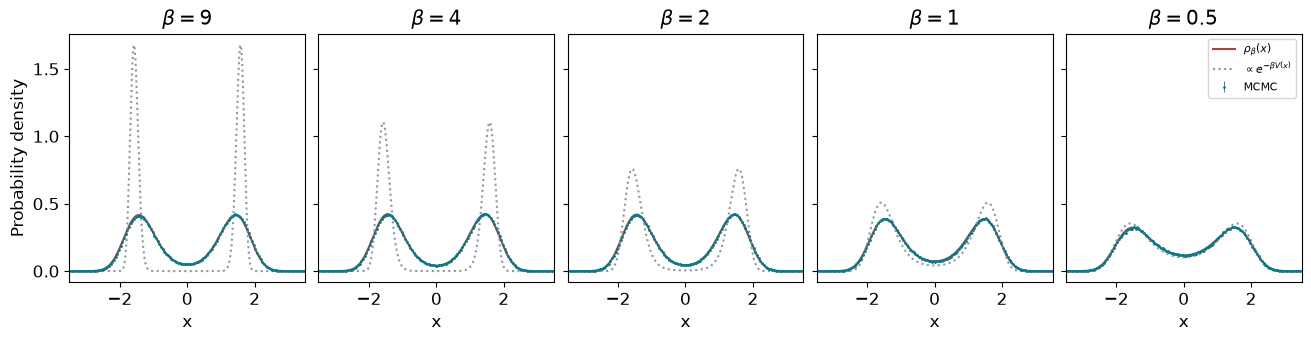

In [17]:
fig, axes = plt.subplots(1, len(BETAS_C), figsize=(13, 3.3), sharey=True)
for ax, (beta, chains) in zip(axes, runs_c.items()):
    mean, error = histogram_with_errors(chains)
    classical = np.exp(-beta * potential(x_grid))
    ax.errorbar(BIN_CENTERS, mean, yerr=error, fmt=".", markersize=2, color=BLUE,
                elinewidth=0.6, label="MCMC")
    ax.plot(x_grid, thermal_density(beta), color=RED, label=r"$\rho_\beta(x)$")
    ax.plot(x_grid, classical / (classical.sum() * dx), ":", color=GRAY,
            label=r"$\propto e^{-\beta V(x)}$")
    ax.set(xlabel="x", xlim=(-3.5, 3.5), title=fr"$\beta = {beta}$")
axes[0].set_ylabel("Probability density")
axes[-1].legend(fontsize=8)
plt.show()

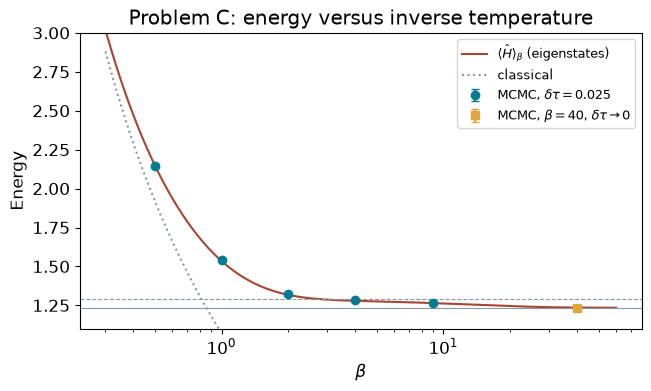

In [18]:
def classical_energy(beta):
    weights = np.exp(-beta * potential(x_grid))
    return 0.5 / beta + np.sum(weights * potential(x_grid)) / weights.sum()


beta_grid = np.geomspace(0.3, 60, 200)
fig, ax = plt.subplots()
ax.plot(beta_grid, [thermal_energy(b) for b in beta_grid], color=RED,
        label=r"$\langle\hat H\rangle_\beta$ (eigenstates)")
ax.plot(beta_grid, [classical_energy(b) for b in beta_grid], ":", color=GRAY, label="classical")
ax.errorbar(BETAS_C, [energies_c[b][0] for b in BETAS_C], yerr=[energies_c[b][1] for b in BETAS_C],
            fmt="o", color=BLUE, capsize=3, label=fr"MCMC, $\delta\tau = {DTAU_C}$")
ax.errorbar([BETA_A], [E0_MC], yerr=[E0_MC_ERROR], fmt="s", color=GOLD, capsize=3,
            label=r"MCMC, $\beta = 40$, $\delta\tau \to 0$")
ax.axhline(E[0], color=GRAY, linewidth=0.8)
ax.axhline(0.5 * (E[0] + E[1]), color=GRAY, linewidth=0.8, linestyle="--")
ax.set(xscale="log", xlabel=r"$\beta$", ylabel="Energy", ylim=(1.1, 3.0),
       title="Problem C: energy versus inverse temperature")
ax.legend(fontsize=9)
plt.show()

### Discussion

**Agreement.** The histograms follow $\rho_\beta(x)$ at every $\beta$, and the energies agree with $\langle\hat H\rangle_\beta$ within $1.4\sigma$ at each of the five temperatures. The energy curve shows three regimes. For $\beta \gtrsim 40$ only $\phi_0$ survives. For $2 \lesssim \beta \lesssim 1/\Delta E$ the energy lies just below $(E_0+E_1)/2$ (dashed line), because $\phi_0$ and $\phi_1$ are still nearly equally populated, and it reaches $E_0$ (solid gray line) only once $\beta\Delta E \gg 1$. For $\beta \lesssim 1$ excited states take over and $\langle \hat H\rangle_\beta$ approaches the classical result.

**Eigenstates and box.** At $\beta = 0.5$, 10 states leave $\langle\hat H\rangle_\beta$ off by $1.6\times 10^{-3}$, comparable to our error bars, while 20 states ($E_{20} \approx 45$, Boltzmann weight $e^{-\beta(E_{20}-E_0)} \approx 10^{-10}$) converge it to $10^{-8}$. The box must hold the thermal density: at $L = 3$, $\beta V(3) \approx 8$, so the walls cut off part of the tail and shift the energy by $0.008$. At $L = 4$, $\beta V(4) \approx 36$ and the result agrees with $L = 6$ to $10^{-8}$. So about 20 states and $L \approx 4$ suffice, and we use 40 states on $L = 6$.

**Meaning of $\rho_\beta$.** $\rho_\beta(x) = \langle x|e^{-\beta\hat H}|x\rangle / Z$ is the diagonal of the canonical density matrix (Lecture 13), the probability density for finding the particle at $x$ in thermal equilibrium at temperature $T = 1/\beta$. In the path integral it is the distribution of any one slice of a closed path. As $\beta \to 0$ the paths shrink to a point, since their spread $\sim\sqrt{\beta}$ is the thermal de Broglie wavelength. Quantum effects then vanish, and $\rho_\beta$ approaches the classical Boltzmann distribution $e^{-\beta V(x)} / \int e^{-\beta V}$ (dotted curves). That curve is already close to $\rho_\beta$ at $\beta = 0.5$ and far from it at $\beta = 9$, where zero-point motion broadens each well. Going further toward $\beta \to 0$, the barrier $V(0) = 2.5$ stops mattering once $\beta V(0) \ll 1$, and the distribution spreads out with width $\sim (\alpha\beta)^{-1/4}$, becoming flat in the limit. The energy approaches the classical value, $\tfrac12 T$ from the kinetic energy plus $\tfrac14 T$ from the quartic potential, about $\tfrac{3}{4\beta}$.

## Summary

| Quantity | Path integral MCMC | Eigenstates (Assignment 2) |
|---|---|---|
| $E_0$ ($\beta = 40$, $\delta\tau \to 0$) | $1.2361 \pm 0.0021$ | $1.2345$ |
| $\Delta E$ (local moves) | $0.111 \pm 0.005$ | $0.1124$ |
| $\Delta E$ (local + shift) | $0.106 \pm 0.003$ | $0.1124$ |
| $\lvert\langle\phi_0\lvert x\rvert\phi_1\rangle\rvert$ (local + shift) | $1.349 \pm 0.004$ | $1.3512$ |
| $\langle\hat H\rangle_\beta$, $\beta = 0.5$ to $9$ | within $1.4\sigma$ at every $\beta$ | |

The main obstacle is tunneling. Local moves change wells only once every $\sim 10^5$ sweeps at $\beta = 20$, so every error bar here comes from 8 independent chains cut into blocks much longer than $\tau_{\text{int}}$. The shift move removes this problem while paths are mostly kink-free ($\beta\Delta E \lesssim 2$), but not at large $\beta$.